John S. Anvik, 2026  
University of Lethbridge Student ID: 001224816

Import Packages

In [1]:
# install.packages("tidymodels")
# install.packages('rlang')
# install.packages("ranger")
# install.packages("rpart.plot")
# install.packages("vip")
library(tidyverse)
library(tidymodels)
library(rpart.plot) # for plotting decision tree
library(vip) # for ranking feature importance
library(ranger) # engine for random forest

# set random seed
set.seed(42)

Warning message:
"package 'tidyverse' was built under R version 4.5.3"
── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.10     ✔ rsample      1.3.1 
✔ dials        1.4.2      ✔ tailor       0.1.0 
✔ infer        1.0.9      ✔ tune         2.0.1 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.3.3      ✔ workflowsets 1.1.1 
✔ recipes      1.3.1      ✔ yardstick    1.3.2 

── Conflicts ─────────────────────

Load data

In [2]:
MODEL_TYPE <- "Hierarchical Classifier All songs since last own song"

data_list <- list()

# TO RUN MODEL ON ALL 11 FOCAL MALES:
folder_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id"
files = list.files(folder_path, full.names=TRUE)

for (file in files) {
    data_list <- append(data_list, list(read_csv(file)))
}

# # TO RUN MODEL ON 1 FOCAL MALE:
# file_path <- "C:\\Users\\johna\\OneDrive\\Documents\\Birdsong\\data\\by_id\\LbOW_song_type_id_frequency.csv" # TODO: Set file path to data for desired focal male
# data_list <- append(data_list, list(read_csv(file_path)))

Rows: 2169 Columns: 363
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (360): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 556 Columns: 365
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (362): UST, time_rel_sunrise, D_M1_M2, D_M1_M3, D_M1_M4, D_M1_M5, D_M1_...
dttm   (1): DateTime

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 1033 Columns: 365
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (2): ID, attention_target_id
dbl  (362): UST, time

In [3]:
# Step 1: Add labels to song types of low, medium, and high quantity songs
    # - How do we determine these labels?
# 2. Remove low quantity songs
# 3. Train two separate classifiers for each focal male, on only medium and high quantity songs
# 4. Train a classifier to determine whether a song is medium or high quantity, then feed it to the relevant classifier

In [4]:
# A lookup table to easily access IDs /ID numbers for each neighbourhood
focal_males <- tibble::tribble(
    ~neighbourhood, ~male_number, ~ID,
    "north",  "1", "LbOW",
    "north",  "2", "RbDgY",
    "north",  "3", "YKY",
    "north",  "4", "TbTbLg",
    "north",  "5", "DgTbO",
    "north",  "6", "RRO",
    "centre", "1", "TbWY",
    "centre", "2", "KRDg",
    "centre", "3", "OPR",
    "centre", "4", "WLpTb",
    "centre", "5", "KLgK",
    "centre", "6", "DgTbO"
)

In [5]:
focal_ids <- list()
for (i in seq_along(data_list)) {
    id <- data_list[[i]] %>% pull(ID) %>% unique()
    # print(id)
    focal_ids[[id]] <- id
}
# focal_ids <- list("LbOW")
names(data_list) <- focal_ids
# names(data_list) <- "LbOW"

In [6]:
map(data_list, ~ head(.x, 3))

ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
DgTbO,25,2022-05-13 05:24:14,-1935.691,NA,NA,NA,NA,NA,NA,⋯,1,1,1,5,5,5,6,6,6,5
DgTbO,20,2022-05-13 05:24:40,-1909.821,NA,NA,NA,NA,NA,NA,⋯,0,0,0,5,5,5,6,6,6,5
DgTbO,1,2022-05-13 05:24:48,-1901.666,NA,NA,NA,NA,NA,NA,⋯,0,0,0,5,5,5,6,6,6,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number
<chr>,<dbl>,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
KLgK,0,2022-05-19 05:11:00,-2609.898,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:15:31,-2338.552,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
KLgK,0,2022-05-19 05:16:36,-2273.861,NA,NA,NA,NA,NA,NA,⋯,3,3,3,4,4,4,5,5,5,5
ID,UST,DateTime,time_rel_sunrise,D_M1_M2,D_M1_M3,D_M1_M4,D_M1_M5,D_M1_M6,M1_last_UST,⋯,M4_1_highest_UST_60_seconds,M4_2_highest_UST_60_seconds,M4_3_highest_UST_60_seconds,M5_1_highest_UST_60_seconds,M5_2_highest_UST_60_seconds,M5_3_highest_UST_60_seconds,M6_1_highest_UST_60_seconds,M6_2_highest_UST_60_seconds,M6_3_highest_UST_60_seconds,male_number


In [7]:
# In data (training AND testing), how many of each song type for the focal male?
for (i in seq_along(data_list)) {
    cat("All song types for", data_list[[i]] %>% pull(ID) %>% unique(), ':\n')
    n_ust <- data_list[[i]] %>%
        group_by(UST) %>%
        summarize(n = n()) %>%
        mutate(percent = 100*n/nrow(data_list[[i]])) %>%
        arrange(desc(percent)) %>%
        # Classes for hierarchical classifer
        mutate(class = case_when(n > 80 ~ as.character(3), n > 30 ~ as.character(2), n > 0 ~ as.character(1), .default = as.character(0)))
    
    data_list[[i]] <- data_list[[i]] %>% left_join(n_ust %>% select(UST, class), by="UST")
    print(n_ust)
    # print(data_list[[i]]$class)
}


All song types for DgTbO :
# A tibble: 29 × 4
     UST     n percent class
   <dbl> <int>   <dbl> <chr>
 1    33   399   18.4  3    
 2    10   286   13.2  3    
 3    20   256   11.8  3    
 4     7   218   10.1  3    
 5     8   214    9.87 3    
 6   153   176    8.11 3    
 7     1   149    6.87 3    
 8    12   102    4.70 3    
 9    11   101    4.66 3    
10    32    80    3.69 2    
# ℹ 19 more rows
All song types for KLgK :
# A tibble: 20 × 4
     UST     n percent class
   <dbl> <int>   <dbl> <chr>
 1     4    77  13.8   2    
 2    10    57  10.3   2    
 3     8    48   8.63  2    
 4    13    45   8.09  2    
 5     0    40   7.19  2    
 6     1    38   6.83  2    
 7    57    36   6.47  2    
 8    55    30   5.40  1    
 9    56    28   5.04  1    
10     5    27   4.86  1    
11    15    26   4.68  1    
12    12    22   3.96  1    
13    14    22   3.96  1    
14     9    18   3.24  1    
15    11    17   3.06  1    
16    58    11   1.98  1    
17     6     7   1.26 

In [8]:
# Set data types and select input columns
for (i in seq_along(data_list) ){
    focal_male_number <- data_list[[i]] %>% pull(male_number) %>% unique()
    data_list[[i]] <- data_list[[i]] %>% 
        mutate(across(contains("UST"), ~ as.factor(.x)),
            # across(contains("ust"), ~ as.integer(.x)), 
            does_it_match = as.factor(does_it_match),
            number_of_matches = as.integer(number_of_matches)) %>%
        select(
            # Response
            "UST",

            # All neighbours' songs since last own song
            contains("n_ust_"),
            -contains("window"), # Don't include the # ust columns that use a time window
            # Own song history (song types)
            sprintf("M%i_1_last_UST", focal_male_number),
            sprintf("M%i_2_last_UST", focal_male_number),
            # sprintf("M%i_3_last_UST", focal_male_number),

            # Own song history (time since last songs)
            sprintf("time_since_M%i_1_last_song", focal_male_number),
            sprintf("time_since_M%i_2_last_song", focal_male_number),        
            # sprintf("time_since_M%i_3_last_song", focal_male_number),
            class
        )  %>%
        drop_na() # drop any row containing at least one NA value
}


In [9]:
# Create model specification
model_tuning_spec <- rand_forest(mtry = tune(), trees = 1000, min_n=tune()) %>%
    set_engine("ranger", importance = "impurity") %>% # importance = impurity measures feature importance (using gini impurity reduction), used for vip() later
    set_mode("classification")

tune_grid <- tidyr::crossing(
    mtry = c(4, 8, 12, 16, 20), # The number of variables randomly sampled as candidates at each split
    min_n = c(2, 5, 10, 15, 20) # Minimum number of data points in a node required for a split
)
eval_metrics <- metric_set(accuracy, precision, recall)

In [10]:
# Train models

models_list <- list()
training_datasets <- list()
testing_datasets <- list()

for (id in focal_ids) {
    class_list <- list()
    training_datasets[[id]] <- list()
    testing_datasets[[id]] <- list()

    for (class in data_list[[id]]$class %>% unique()) {
        data <- data_list[[id]] %>% filter(class == class) %>% select(-class)
        # train test split
        train_test_split <- initial_split(data, prop = 0.7, strata=UST)

        train_data <- train_test_split %>% training()
        training_datasets[[id]][[class]] <- train_data
        test_data <- train_test_split %>% testing()
        testing_datasets[[id]][[class]] <- test_data

        # In training data, how many of each song type?
        n_ust <- train_data %>%
            group_by(UST) %>%
            summarize(n = n()) %>%
            mutate(percent = 100*n/nrow(train_data)) %>%
            arrange(percent)
        n_ust

        # use v-fold cross validation to assess model accuracy
        v <- 5
        train_vfold <- vfold_cv(train_data, v=v, strata = UST)



        # Data preprocessing using a recipe
        recipe <- recipe(UST ~ ., data = train_data) %>%
            step_scale(all_numeric()) %>% # scale all numeric predictors
            step_center(all_numeric()) # center all numeric predictors


        model_tuning <- workflow() %>%
            add_recipe(recipe) %>%
            add_model(model_tuning_spec) %>%

        tune_grid(resamples = train_vfold, grid=tune_grid, metrics = eval_metrics) # for v-fold cross validation, tuning k parameter
        # fit(data = train_data) # to train on whole train set with no validation set

        model_tuning

        # Accuracies listed use 5-fold cross validation
        model_tuning_accuracies <- model_tuning %>% collect_metrics() %>% arrange(.metric) #  %>% filter(.metric == "accuracy")
        model_tuning_accuracies

        # plot accuracies of all values of hyperparameters

        ggplot(model_tuning_accuracies %>% filter(.metric == "accuracy")) +
            geom_tile(aes(x=mtry, y=min_n, fill=mean)) +
            geom_text(aes(x=mtry, y=min_n, label=round(mean, 2), size=5)) +
            labs(x = "Randomly Sampled Variables", y = "Minimum Samples to Split", color="Estimated Accuracy", title="Accuracy") +
            theme(text = element_text(size=20)) +
            scale_fill_gradient(low="white", high="red")

        # Print best hyperparameter values
        best_params <- model_tuning_accuracies %>% arrange(desc(mean)) %>% head(1) %>% pull(mtry, min_n)
        print("Best hyperparameters: (mtry, min_n)")
        print(best_params)

        # retrain model on best parameters
        best_params <- model_tuning %>%
        select_best()
        print("Best Parameters:")
        print(best_params)

        model <- workflow() %>%
            add_recipe(recipe) %>%
            add_model(model_tuning_spec) %>%
            finalize_workflow(best_params) %>%
            # fit_resamples(resamples = train_vfold) # for v-fold cross validation
            fit(data = train_data) # to train on whole train set with no validation set

        
        class_list[[class]] <- model
    }
    models_list[[id]] <- class_list
}
names(models_list) <- focal_ids
names(training_datasets) <- focal_ids
names(testing_datasets) <- focal_ids


→ A | warning: Dropped unused factor level(s) in dependent variable: 13, 158, 161, 162.

There were issues with some computations   A: x1

There were issues with some computations   A: x6

There were issues with some computations   A: x21

There were issues with some computations   A: x36

There were issues with some computations   A: x55

There were issues with some computations   A: x66

There were issues with some computations   A: x78

There were issues with some computations   A: x91

There were issues with some computations   A: x105

There were issues with some computations   A: x136

There were issues with some computations   A: x153

There were issues with some computations   A: x171

There were issues with some computations   A: x190

There were issues with some computations   A: x210

There were issues with some computations   A: x231

There were issues with some computations   A: x253

There were issues with some computations   A: x276

There were issues with some computati

[1] "Best hyperparameters: (mtry, min_n)"
20 
 8 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    12    20 pre0_mod15_post0


Warning message:
"Dropped unused factor level(s) in dependent variable: 13, 158, 161."
→ A | warning: Dropped unused factor level(s) in dependent variable: 158, 163.

There were issues with some computations   A: x1

There were issues with some computations   A: x15

There were issues with some computations   A: x36

There were issues with some computations   A: x55

There were issues with some computations   A: x78

There were issues with some computations   A: x91

There were issues with some computations   A: x105

There were issues with some computations   A: x136

There were issues with some computations   A: x153

There were issues with some computations   A: x171

There were issues with some computations   A: x190

There were issues with some computations   A: x210

There were issues with some computations   A: x231

There were issues with some computations   A: x253

There were issues with some computations   A: x276

There were issues with some computations   A: x300

There we

[1] "Best hyperparameters: (mtry, min_n)"
20 
 4 


... (110 outputs left out)

Warning message:
"Dropped unused factor level(s) in dependent variable: 26, 168."
Warning message:
"Too little data to stratify.
• Resampling will be unstratified."
Warning message:
"Too little data to stratify.
• Resampling will be unstratified."
→ A | warning: Dropped unused factor level(s) in dependent variable: 26, 29, 168.

There were issues with some computations   A: x1

There were issues with some computations   A: x21

There were issues with some computations   A: x66

There were issues with some computations   A: x91

There were issues with some computations   A: x136

There were issues with some computations   A: x171

There were issues with some computations   A: x231

There were issues with some computations   A: x253

There were issues with some computations   A: x300

→ B | warning: While computing multiclass `precision()`, some levels had no predicted events
               (i.e. `true_positive + false_positive = 0`).
               Precision is undefined in this case, a

[1] "Best hyperparameters: (mtry, min_n)"
2 
4 


Warning message in select_best(.):
"No value of `metric` was given; "accuracy" will be used."


[1] "Best Parameters:"
# A tibble: 1 × 3
   mtry min_n .config         
  <dbl> <dbl> <chr>           
1    16    20 pre0_mod20_post0


In [11]:
models <- tibble(
    id = focal_ids,
    models = list(models_list),
    train_data = list(training_datasets),
    test_data = list(testing_datasets)
)

In [12]:
final_predictions_list <- list()

for (id in focal_ids) {
    
    # Check if this ID actually exists in our models
    if (!(id %in% names(models_list))) {
        warning(paste("ID", id, "not found in models_list"))
        next
    }

    # Get the classes available for this specific male
    available_classes <- names(models_list[[id]])
    
    male_results <- map_dfr(available_classes, function(class_name) {
        
        # 1. Extract the model
        current_model <- models_list[[id]][[class_name]]
        
        # 2. Extract the data safely using [[ ]] or filter()
        # Using the specific class-based test set you created earlier
        class_test_subset <- testing_datasets[[id]][[class_name]]
        
        # Sanity check: does data exist for this class?
        if (!is.null(class_test_subset) && nrow(class_test_subset) > 0) {
            
            preds <- predict(current_model, class_test_subset)
            
            # Combine and return
            return(bind_cols(preds, class_test_subset) %>%
                mutate(focal_id = id, assigned_class = class_name))
        } else {
            return(NULL) # Skip if no data
        }
    })
    
    # Only add to list if we actually got results
    if (nrow(male_results) > 0) {
        final_predictions_list[[id]] <- male_results
    }
}

# Final merge
all_results <- bind_rows(final_predictions_list)

# Check the output
print(paste("Rows in all_results:", nrow(all_results)))
head(all_results)

[1] "Rows in all_results: 7920"


.pred_class,UST,n_ust_1,n_ust_3,n_ust_4,n_ust_5,n_ust_6,n_ust_7,n_ust_8,n_ust_9,⋯,time_since_M1_1_last_song,time_since_M1_2_last_song,M3_1_last_UST,M3_2_last_UST,time_since_M3_1_last_song,time_since_M3_2_last_song,M4_1_last_UST,M4_2_last_UST,time_since_M4_1_last_song,time_since_M4_2_last_song
<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,⋯,<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>
33,33,0,0,0,1,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
153,153,0,0,0,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
33,8,0,0,0,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
10,33,0,0,0,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
7,10,0,0,0,0,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
1,8,0,0,0,1,0,0,0,0,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


In [13]:
library(yardstick)

# Total Global Accuracy
total_perf <- all_results %>%
  metrics(truth = UST, estimate = .pred_class)

# Accuracy per Focal Male
male_perf <- all_results %>%
  group_by(focal_id) %>%
  metrics(truth = UST, estimate = .pred_class)

# Accuracy per Class (to see if "Rare" classes perform worse than "Common")
class_perf <- all_results %>%
  group_by(assigned_class) %>%
  metrics(truth = UST, estimate = .pred_class)

print(male_perf)

# A tibble: 22 × 4
   focal_id .metric  .estimator .estimate
   <chr>    <chr>    <chr>          <dbl>
 1 DgTbO    accuracy multiclass     0.253
 2 KLgK     accuracy multiclass     0.223
 3 KRDg     accuracy multiclass     0.364
 4 LbOW     accuracy multiclass     0.274
 5 OPR      accuracy multiclass     0.478
 6 RRO      accuracy multiclass     0.315
 7 RbDgY    accuracy multiclass     0.303
 8 TbTbLg   accuracy multiclass     0.25 
 9 TbWY     accuracy multiclass     0.452
10 WLpTb    accuracy multiclass     0.247
# ℹ 12 more rows


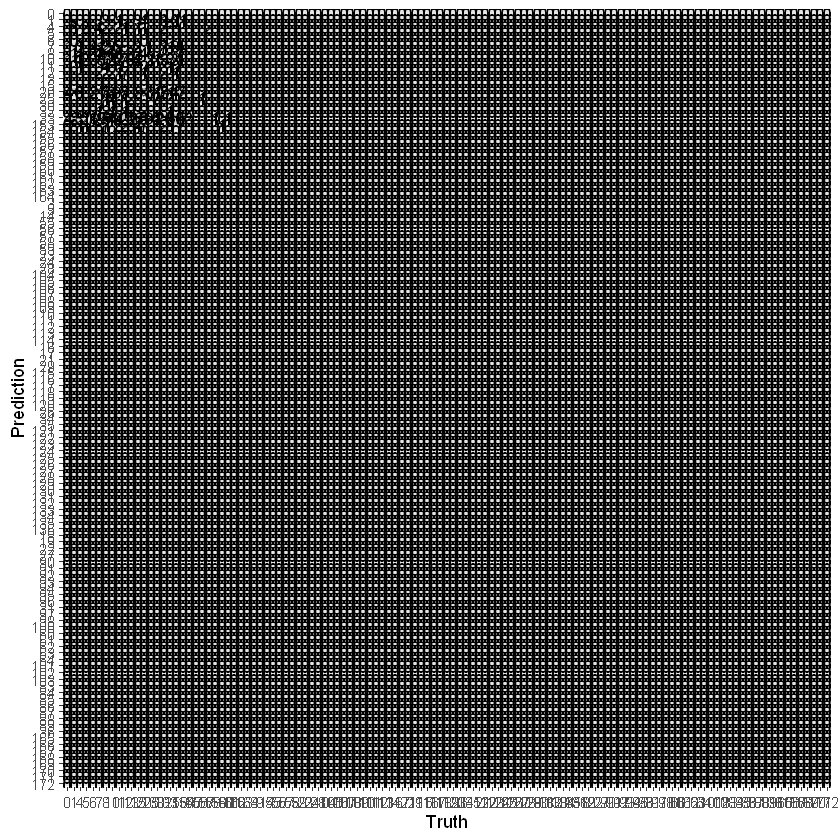

In [19]:
# Visualizing the confusion for a specific male
all_results %>%
  filter(focal_id == focal_ids[1]) %>%
  conf_mat(truth = UST, estimate = .pred_class) %>%
  autoplot(type = "heatmap")

In [16]:
for (id in focal_ids) {
  model <- models_list[[id]]
  male_number <- focal_males %>% filter(ID == id) %>% pull(male_number)
  neighbourhood <- focal_males %>% filter(ID == id) %>% pull(neighbourhood)
  importance_chart <- model %>% extract_fit_engine() %>% vip(num_features=10) +
    labs(title=paste(id, MODEL_TYPE, male_number, neighbourhood)) +
    theme_bw() + # Starting with a clean theme
    theme(
      axis.text.x = element_text(size = 14),       # X-axis tick labels
      axis.text.y = element_text(size = 12),       # Y-axis tick labels
      axis.title.x = element_text(size = 16),      # X-axis title
      axis.title.y = element_text(size = 16),      # Y-axis title
      plot.title = element_text(size = 16, face = "bold"), # Main plot title
      legend.text = element_text(size = 12),       # Legend labels
      legend.title = element_text(size = 14)       # Legend title
    )
  print(importance_chart)
  cat(id, male_number, '\n')
  ggsave(paste(MODEL_TYPE, id, "importance.png"), plot=importance_chart)
}


ERROR: Error in UseMethod("extract_fit_engine"): no applicable method for 'extract_fit_engine' applied to an object of class "list"


In [ ]:
# Predict on the test set, and create a new DataFrame with inputs and outputs
# Return the accuracy, precision, and recall of our model

all_test_accuracies = tibble()
all_song_accuracies = tibble()

for (id in focal_ids) {
    View(id)
    test_data <- testing_datasets[[id]]
    model <- models_list[[id]]
    test_predictions <- model %>% predict(test_data) %>%
        bind_cols(test_data)
    test_accuracy <- test_predictions %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        rename(estimated_accuracy = .estimate) %>%
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, estimated_accuracy, model)
        # TODO: Add other features such as repertoire size, size of territory, neighbourhood
        #%>% pull(.estimate) %>% round(3)
    View(test_accuracy)
    all_test_accuracies <- all_test_accuracies %>% bind_rows(test_accuracy)

    test_song_accuracies <- test_predictions %>% group_by(UST) %>% 
        metrics(truth = UST, estimate = .pred_class) %>% 
        filter(.metric == "accuracy") %>% 
        arrange(desc(.estimate)) %>% 
        mutate(ID = id, model=MODEL_TYPE) %>%
        select(ID, UST, .estimate, model) %>% 
        rename(estimated_accuracy = .estimate) %>%
        left_join(n_ust %>% select(UST, n), by = "UST")
    View(test_song_accuracies)
    all_song_accuracies <- all_song_accuracies %>% bind_rows(test_song_accuracies)

    # View(test_predictions %>% group_by(UST) %>% precision(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Precision = correct positive predictions / total positive predictions
    # View(test_predictions %>% group_by(UST) %>% recall(truth = UST, estimate = .pred_class, event_level = "multiclass") %>% arrange(desc(.estimate))) # Recall = correct positive predictions / total positive test set observations

    confusion_matrix <- test_predictions %>%
    conf_mat(truth = UST, estimate = .pred_class)
    print(confusion_matrix)
}

In [ ]:
filename <- paste0("data/results/", MODEL_TYPE, "_test_accuracies.csv")
print(filename)
write_csv(all_test_accuracies, filename)

filename <- paste0("data/results/", MODEL_TYPE, "_song_accuracies.csv")
print(filename)
write_csv(all_song_accuracies, filename)